# ΕΡΓΑΣΙΑ 2 - Timeseries

### ΕΙΣΑΓΩΓΗ ΒΙΒΛΙΟΘΗΚΩΝ

In [128]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning
import warnings

## ΜΕΡΟΣ 2 - Timeseries

In [123]:
ticker_symbol = 'DX-Y.NYB'

ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='10y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df

,Date,Open,High,Low,Close
0,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997
1,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
2,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
3,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
4,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000
...,...,...,...,...,...
2509,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998
2510,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999
2511,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000
2512,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002


### ΕΡΩΤΗΜΑ 1

**ΠΕΡΙΓΡΑΦΗ ΧΑΡΑΚΤΗΡΙΣΤΙΚΩΝ**

Πρόκειται για μεταβλητές της χρηματιστηριακής αγοράς, για μια χρηματιστηριακή συνεδρίαση

* **Open**: Τιμή ανοίγματος του δείκτη στην έναρξη της χρηματιστηριακής συνεδρίασης
* **Low**: Ελάχιστη τιμή του δείκτη για την συγκεκριμένη συνεδρίαση
* **High**: Μέγιστη τιμή του δείκτη για την συγκεκριμένη συνεδρίαση
* **Close**: Τιμή κλεισίματος του δείκτη στην λήξη της χρηματιστηριακής συνεδρίασης

In [124]:
#Mean
print(df.mean())

Date     2021-10-31 02:16:39.522672896-04:00
Open                                98.79956
High                               99.100393
Low                                98.509801
Close                              98.809665
dtype: object


In [125]:
#Standard deviation
print(df.std())

Date     1054 days 01:19:42.778148944
Open                         4.971375
High                         5.018975
Low                          4.915228
Close                        4.972964
dtype: object


In [126]:
#Create line
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='US Dollar from 2016 to 2026')
fig.update_layout(
    autosize=False,
    width=2200,
    height=1000
)
fig.show()

### ΕΡΩΤΗΜΑ 2

Από το πολύγωνο παρατηρούμε ότι οι χρονοσειρές είναι μη στάσιμες, καθώς για μεγάλα χρονικά διαστήματα κινούνται μακριά από τη μέση τιμή, έχοντας έντονη ανοδική ή καθοδική κλίση. Επίσης η τάση της χρονοσειράς αλλάζει και δεν είναι σταθερή στο χρόνο. Υπάρχουν παρατεταμένα χρονικά διαστήματα (πρώτο εξάμηνο 2021) όπου κινείται σε πολύ χαμηλά επίπεδα, και άλλα (2022-2025) όπου κινείται σε πολύ υψηλά επίπεδα.

### ΕΡΩΤΗΜΑ 3

In [129]:
#Calculate ADF, KPSS
adf_results = []
kpss_results = []
cols = ['High', 'Close', 'Low']

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)

for col in cols:
  tseries = df[col]
  adf = adfuller(tseries)
  adf_results.append({'Timeseries': col, 'ADF': adf[0], 'p-value': adf[1], 'Non Stationary (p >= 0.05)': adf[1] >= 0.05})
  kpss_model = kpss(tseries)
  kpss_results.append({'Timeseries': col, 'KPSS': kpss_model[0], 'p-value': kpss_model[1], 'Non Stationary (p < 0.05)': kpss_model[1] < 0.05})

adf_df = pd.DataFrame(adf_results)
kpss_df = pd.DataFrame(kpss_results)
display(adf_df)
display(kpss_df)

,Timeseries,ADF,p-value,Non Stationary (p >= 0.05)
0,High,-1.889641,0.336950,True
1,Close,-1.884791,0.339249,True
2,Low,-1.978827,0.295933,True


,Timeseries,KPSS,p-value,Non Stationary (p < 0.05)
0,High,2.813586,0.01,True
1,Close,2.837127,0.01,True
2,Low,2.863425,0.01,True


Παρατηρούμε ότι οι στατιστικές μέθοδοι ADF και KPSS επιβεβαιώνουν την μη στασιμότητα των χρονοσειρών, που υποθέσαμε νωρίτερα. Πιο συγκεκριμένα, με την τεχνική ADF, έχουμε μη στασιμότητα όταν p >= 0.05 ενώ με την τεχνική KPSS έχουμε μη στασιμότητα όταν p < 0.05 .

### ΕΡΩΤΗΜΑ 4

In [130]:
#Train-Test split
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((1759, 5), (785, 5))

### ΕΡΩΤΗΜΑ 5

In [131]:
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

In [132]:
train_df.head(5)

,Date,Open,High,Low,Close
0,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997
1,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
2,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
3,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
4,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000


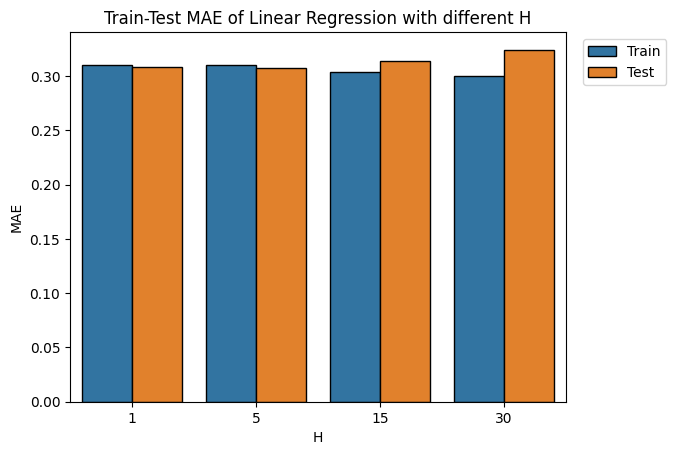

In [133]:
#Train the model, run predictions, create barplot for different H values
history_size_list = [1,5,15,30]
lr_results = []

for h in history_size_list:
    x_train, y_train = construct_timeframes(train_df, h)
    x_test, y_test = construct_timeframes(test_df, h)

    model = LinearRegression()
    model.fit(x_train, y_train)

    y_prediction_train = model.predict(x_train)
    train_mae = mean_absolute_error(y_true=y_train, y_pred=y_prediction_train)
    y_prediction_test = model.predict(x_test)
    test_mae = mean_absolute_error(y_true=y_test, y_pred=y_prediction_test)

    lr_results.append({'H': h, 'Dataset': 'Train', 'MAE': train_mae})
    lr_results.append({'H': h, 'Dataset': 'Test', 'MAE': test_mae})

metrics_df = pd.DataFrame(lr_results)
ax = sns.barplot(metrics_df, x='H', y='MAE', hue='Dataset', edgecolor='black')
ax.set_title('Train-Test MAE of Linear Regression with different H')
ax.legend(bbox_to_anchor=(1.02,1))
plt.show();

Η μετρική που χρησιμοποιούμε είναι το Μέσο Απόλυτο Σφάλμα (**Mean Absolute Error**, MAE) καθώς έχει φυσική σημασία και ερμηνεύει πιο άμεσα τα σφάλματα.

### ΕΡΩΤΗΜΑ 6

In [134]:
history_size = 30
train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]

# Create figure
fig = go.Figure()

#Actual training data (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train)[-history_size:],
    mode='lines',
    name='Train (Actual)',
    line=dict(color='royalblue', width=2)
))

#Prediction line for train set (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_prediction_train)[-history_size:],
    mode='lines',
    name='Train (Predicted)',
    line=dict(color='yellow', width=2)
))

# Test actual values
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Vertical dashed line separating train/test
fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=0,
    y1=1,
    xref='x',
    yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

# Prediction line for test set
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_prediction_test),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

# Layout
fig.update_layout(
    title='US Dollar Price Index — Close Price Prediction',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified'
)

fig.show()

Παρατηρούμε ότι η πρόβλεψη ακολουθεί ικανοποιητικά την γενική τάση της χρονοσειράς, ωστόσο οι προβλεπόμενες τιμές δεν ακολουθούν με ακρίβεια τις πραγματικές τιμές. Δεν μπορεί να αποτυπώσει πάντα με ακρίβεια τις απότομες αλλαγές των τιμών.

### ΕΡΩΤΗΜΑ 7

In [135]:
vars = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()
df_logr[vars] = np.log(df_logr[vars]/df_logr[vars].shift(1))
df_logr

,Date,Open,High,Low,Close
0,2016-10-31 00:00:00-04:00,NaN,NaN,NaN,NaN
1,2016-11-01 00:00:00-04:00,0.000712,-0.002231,-0.006635,-0.007647
2,2016-11-02 00:00:00-04:00,-0.006526,-0.006929,-0.004722,-0.003075
3,2016-11-03 00:00:00-04:00,-0.003792,-0.003483,-0.001442,-0.002467
4,2016-11-04 00:00:00-04:00,-0.002262,-0.001129,-0.001547,-0.000927
...,...,...,...,...,...
2509,2026-10-23 00:00:00-04:00,-0.001377,-0.000294,0.000394,0.001966
2510,2026-10-26 00:00:00-04:00,0.002065,0.002060,0.000886,0.001472
2511,2026-10-27 00:00:00-04:00,0.002453,0.003326,0.004028,0.003525
2512,2026-10-28 00:00:00-04:00,0.003327,0.000878,0.000588,-0.001271


Παρατηρούμε ότι η πρώτη γραμμή δεν έχει τιμές (NaN) λόγω της εφαρμογής του Log-Returns

In [136]:
#Drop NaN
df_logr = df_logr.dropna().reset_index(drop=True)
df.shape, df_logr.shape

((2514, 5), (2513, 5))

In [137]:
#Check for NaN
print(df_logr.isna().any())

Date     False
Open     False
High     False
Low      False
Close    False
dtype: bool


In [138]:
#Convert to absolute price
def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)

In [139]:
valid_df = pd.DataFrame({
    'Date': df['Date'].iloc[: 6],
    'Close': df['Close'].iloc[: 6],
    'Close-Log-Returns': df_logr['Close'].iloc[: 6]
})
valid_df

,Date,Close,Close-Log-Returns
0,2016-10-31 00:00:00-04:00,98.449997,-0.007647
1,2016-11-01 00:00:00-04:00,97.699997,-0.003075
2,2016-11-02 00:00:00-04:00,97.400002,-0.002467
3,2016-11-03 00:00:00-04:00,97.160004,-0.000927
4,2016-11-04 00:00:00-04:00,97.070000,0.007288
5,2016-11-07 00:00:00-05:00,97.779999,0.000818


In [143]:
#New train-test split
train_df_logr = df_logr.iloc[:num_train_samples - 1]
test_df_logr = df_logr.iloc[:num_train_samples - 1 - history_size:]

In [144]:
#Run the model again and predict
logr_preds = {}

for h in history_size_list:
  x_train, y_train = construct_timeframes(train_df_logr, h)
  x_test, y_test = construct_timeframes(test_df_logr, h)

  new_model = LinearRegression()
  new_model.fit(x_train, y_train)

  y_prediction_train_new = new_model.predict(x_train)
  y_prediction_test_new = new_model.predict(x_test)

  logr_preds[h] = {'y_train': y_train, 'y_prediction_train_new': y_prediction_train_new, 'y_test': y_test, 'y_prediction_test_new': y_prediction_test_new}
  logr_preds

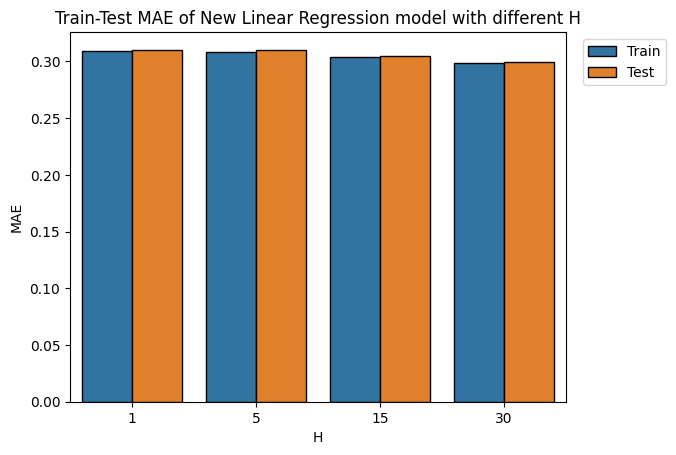

In [145]:
#Collect predictions and calculate MAE
logr_results = []

#Μap dates to their index in the original df
date_to_idx = pd.Series(
    np.arange(len(df)),
    index=pd.to_datetime(df['Date'])
)

for h in history_size_list:
  pred_train = logr_preds[h]['y_prediction_train_new']
  pred_test = logr_preds[h]['y_prediction_test_new']

  train_dates = train_df_logr['Date'].iloc[h:]
  test_dates = test_df_logr['Date'].iloc[h:]

  #Match rows in the original df
  train_idx = date_to_idx.reindex(train_dates).to_numpy(dtype=int)
  test_idx = date_to_idx.reindex(test_dates).to_numpy(dtype=int)

  original_close_prices = df['Close'].to_numpy()

  new_close_prices_train = original_close_prices[train_idx]
  new_close_prices_test = original_close_prices[test_idx]

  previous_close_train = original_close_prices[train_idx - 1]
  previous_close_test = original_close_prices[test_idx - 1]

  #Convert back to absolute prices
  predicted_train_prices = log_returns_to_absolute_prices(previous_close_train, pred_train)
  predicted_test_prices = log_returns_to_absolute_prices(previous_close_test, pred_test)

  train_mae = mean_absolute_error(y_true=new_close_prices_train, y_pred=predicted_train_prices)
  test_mae = mean_absolute_error(y_true=new_close_prices_test, y_pred=predicted_test_prices)

  logr_results.append({'H': h, 'Dataset': 'Train', 'MAE': train_mae})
  logr_results.append({'H': h, 'Dataset': 'Test', 'MAE': test_mae})

logr_metrics_df = pd.DataFrame(logr_results)
ax = sns.barplot(logr_metrics_df, x='H', y='MAE', hue='Dataset', edgecolor='black')
ax.set_title('Train-Test MAE of New Linear Regression model with different H')
ax.legend(bbox_to_anchor=(1.02,1))
plt.show();

### ΕΡΩΤΗΜΑ 8

In [146]:
data = train_df[['Close', 'Open']]

#Calculating log-returns
data = np.log(data/data.shift(1)).dropna()

#Test up to history_size lags
results = grangercausalitytests(data[['Close', 'Open']], maxlag=history_size)

#Extract p-values
p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, history_size + 1)
}
results_df = pd.DataFrame({'Lag (H)': list(p_values.keys()), 'P-value': list(p_values.values())})
results_df['Significant'] = results_df['P-value'] < 0.05
results_df

,Lag (H),P-value,Significant
0,1,0.191609,False
1,2,0.820257,False
2,3,0.525268,False
3,4,0.785338,False
4,5,0.025691,True
5,6,0.636667,False
6,7,0.725205,False
7,8,0.392926,False
8,9,0.278278,False
9,10,0.493648,False


Παρατηρούμε ότι p < 0.05 για lag = 4, συνεπώς η μεταβλητή Open είναι χρήσιμη (Significant) για την πρόβλεψη του Close μέχρι εκείνο το χρονικό παράθυρο.

### ΕΡΩΤΗΜΑ 9

In [147]:
sp500_ticker = yf.Ticker('^GSPC')

#Create S&P500 dataframe
sp500 = sp500_ticker.history(period='10y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)

#Keep only Date and Close, since Close is the extra feature from S&P500 to be included
sp500 = sp500[['Date', 'Close']]
sp500 = sp500.rename(columns={'Close': 'sp500'})
sp500

,Date,sp500
0,2016-10-31 00:00:00-04:00,2126.149902
1,2016-11-01 00:00:00-04:00,2111.719971
2,2016-11-02 00:00:00-04:00,2097.939941
3,2016-11-03 00:00:00-04:00,2088.659912
4,2016-11-04 00:00:00-04:00,2085.179932
...,...,...
2507,2026-10-22 00:00:00-04:00,7663.430176
2508,2026-10-23 00:00:00-04:00,7623.680176
2509,2026-10-26 00:00:00-04:00,7676.770020
2510,2026-10-27 00:00:00-04:00,7722.600098


In [148]:
#Match the dates between the dataframes so that they are consistent, being in different timezones blocks the merge
df['Date'] = pd.to_datetime(df['Date']).dt.tz_localize(None).dt.normalize()
sp500['Date'] = pd.to_datetime(sp500['Date']).dt.tz_localize(None).dt.normalize()

#Bring both dates into the same datetime format
sp500['Date'] = pd.to_datetime(sp500['Date']).dt.strftime('%Y-%m-%d')
df['Date'] = pd.to_datetime(df['Date']).dt.strftime('%Y-%m-%d')
sp500

,Date,sp500
0,2016-10-31,2126.149902
1,2016-11-01,2111.719971
2,2016-11-02,2097.939941
3,2016-11-03,2088.659912
4,2016-11-04,2085.179932
...,...,...
2507,2026-10-22,7663.430176
2508,2026-10-23,7623.680176
2509,2026-10-26,7676.770020
2510,2026-10-27,7722.600098


In [149]:
#Merge the dataframes
df = df.merge(sp500, on='Date', how='left')
df

,Date,Open,High,Low,Close,sp500
0,2016-10-31,98.320000,98.699997,98.290001,98.449997,2126.149902
1,2016-11-01,98.389999,98.480003,97.639999,97.699997,2111.719971
2,2016-11-02,97.750000,97.800003,97.180000,97.400002,2097.939941
3,2016-11-03,97.379997,97.459999,97.040001,97.160004,2088.659912
4,2016-11-04,97.160004,97.349998,96.889999,97.070000,2085.179932
...,...,...,...,...,...,...
2509,2026-10-23,101.570000,101.849998,101.489998,101.809998,7623.680176
2510,2026-10-26,101.779999,102.059998,101.580002,101.959999,7676.770020
2511,2026-10-27,102.029999,102.400002,101.989998,102.320000,7722.600098
2512,2026-10-28,102.370003,102.489998,102.050003,102.190002,7743.979980


In [150]:
#Find any NaN values in sp500
print(df[df['sp500'].isna()][['Date', 'Close', 'sp500']])

            Date       Close  sp500
2059  2025-01-09  109.180000    NaN
2153  2025-05-26   98.930000    NaN
2513  2026-10-29  102.247002    NaN


In [151]:
#Forward fill missing values
df['sp500'] = df['sp500'].ffill()
print(df[df['sp500'].isna()][['Date', 'Close', 'sp500']])

Empty DataFrame
Columns: [Date, Close, sp500]
Index: []


In [152]:
#Drop NaN values in case the first row is NaN and not covered by forward fill
df = df.dropna().reset_index(drop=True)
df.shape

(2514, 6)

In [158]:
df['Date'] = pd.to_datetime(df['Date'])

#Adding calendar features and holidays
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek  # Monday=0, Sunday=6

us_holidays = holidays.country_holidays('US')

#Combine US holiday into dataframe
df['Holiday'] = df['Date'].dt.date.map(
    lambda d: int(
        d in us_holidays
    )
)
df

,Date,Open,High,Low,Close,sp500,Month,DayOfWeek,Holiday
0,2016-10-31,98.320000,98.699997,98.290001,98.449997,2126.149902,10,0,0
1,2016-11-01,98.389999,98.480003,97.639999,97.699997,2111.719971,11,1,0
2,2016-11-02,97.750000,97.800003,97.180000,97.400002,2097.939941,11,2,0
3,2016-11-03,97.379997,97.459999,97.040001,97.160004,2088.659912,11,3,0
4,2016-11-04,97.160004,97.349998,96.889999,97.070000,2085.179932,11,4,0
...,...,...,...,...,...,...,...,...,...
2509,2026-10-23,101.570000,101.849998,101.489998,101.809998,7623.680176,10,4,0
2510,2026-10-26,101.779999,102.059998,101.580002,101.959999,7676.770020,10,0,0
2511,2026-10-27,102.029999,102.400002,101.989998,102.320000,7722.600098,10,1,0
2512,2026-10-28,102.370003,102.489998,102.050003,102.190002,7743.979980,10,2,0


In [159]:
#Redefine construct_timeframes to include future features
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date', 'Month', 'DayOfWeek', 'Holiday']).to_numpy(dtype=np.float64)
    future_features = df[['Month', 'DayOfWeek', 'Holiday']].to_numpy(dtype=np.float64)
    x = np.array([np.concatenate([inputs[i-H: i].flatten(), future_features[i]]) for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

In [160]:
#Train-Test split again because of dropped rows
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((1759, 9), (785, 9))

In [161]:
#Retrain the model and run predictions
history_size_list = [1,5,15,30]
final_results = []

for h in history_size_list:
    x_train, y_train = construct_timeframes(train_df, h)
    x_test, y_test = construct_timeframes(test_df, h)

    model = LinearRegression()
    model.fit(x_train, y_train)

    y_prediction_train = model.predict(x_train)
    train_mae = mean_absolute_error(y_true=y_train, y_pred=y_prediction_train)
    y_prediction_test = model.predict(x_test)
    test_mae = mean_absolute_error(y_true=y_test, y_pred=y_prediction_test)

    final_results.append({'H': h, 'Dataset': 'Train', 'MAE': train_mae})
    final_results.append({'H': h, 'Dataset': 'Test', 'MAE': test_mae})

final_results_df = pd.DataFrame(final_results)
final_results_df

,H,Dataset,MAE
0,1,Train,0.310030
1,1,Test,0.307496
2,5,Train,0.305273
3,5,Test,0.312304
4,15,Train,0.298187
5,15,Test,0.321087
6,30,Train,0.292093
7,30,Test,0.337369


In [162]:
#Repeat Task 6 and plot line
history_size = 30
train_dates = train_df['Date'].iloc[history_size:]
test_dates = test_df['Date'].iloc[history_size:]

# Create figure
fig = go.Figure()

#Actual training data (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_train)[-history_size:],
    mode='lines',
    name='Train (Actual)',
    line=dict(color='royalblue', width=2)
))

#Prediction line for train set (last history_size samples only)
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-history_size:],
    y=np.ravel(y_prediction_train)[-history_size:],
    mode='lines',
    name='Train (Predicted)',
    line=dict(color='purple', width=2)
))

# Test actual values
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_test),
    mode='lines',
    name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))

# Vertical dashed line separating train/test
fig.add_shape(
    type='line',
    x0=test_dates.iloc[0],
    x1=test_dates.iloc[0],
    y0=0,
    y1=1,
    xref='x',
    yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

# Prediction line for test set
fig.add_trace(go.Scatter(
    x=test_dates,
    y=np.ravel(y_prediction_test),
    mode='lines',
    name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

# Layout
fig.update_layout(
    title='US Dollar Price Index — Close Price Prediction using Future Features',
    xaxis_title='Date',
    yaxis_title='Price ($)',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified'
)

fig.show()